# F1 Intelligence ML - data exploration

This notebook inspects the processed tables and the leakage-safe feature dataset.
Run `python scripts/collect_data.py --start 1995 --end 2026` and
`python scripts/build_dataset.py` first.

In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
while not (project_root / 'config.py').exists() and project_root.parent != project_root:
    project_root = project_root.parent
if not (project_root / 'config.py').exists():
    raise RuntimeError('Run this notebook from the project or notebooks directory')
sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt

import config
from src.features.feature_engineering import load_feature_dataset, load_constructor_dataset

dataset = load_feature_dataset()
constructor_dataset = load_constructor_dataset()
print(dataset.shape, constructor_dataset.shape)
dataset[['season', 'round', 'race_id', 'driver_id', 'finish_position', 'win', 'podium']].head()

(12299, 282) (6270, 211)


,season,round,race_id,driver_id,finish_position,win,podium
0,1995,1,1995_01,coulthard,2.0,0,1
1,1995,1,1995_01,berger,3.0,0,1
2,1995,1,1995_01,hakkinen,4.0,0,0
3,1995,1,1995_01,alesi,5.0,0,0
4,1995,1,1995_01,blundell,6.0,0,0


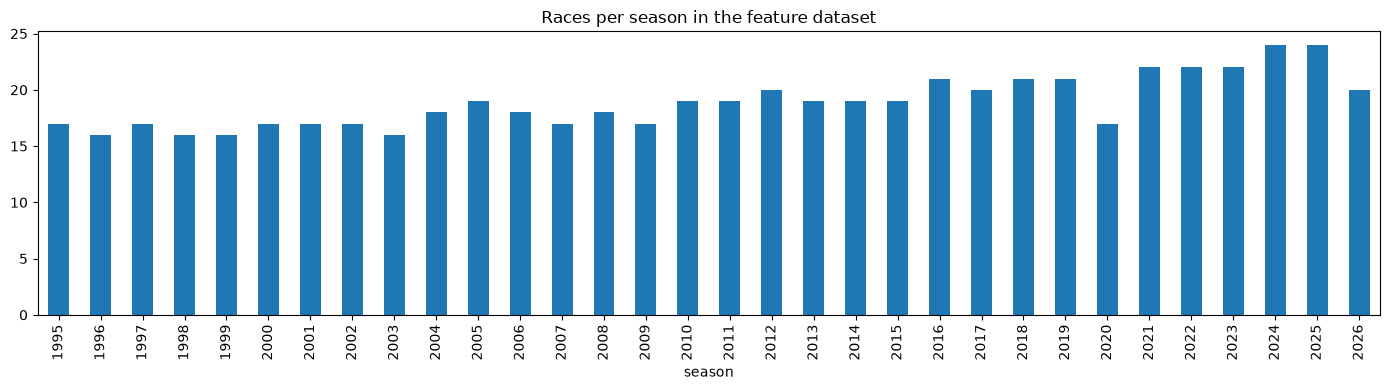

In [2]:
races_per_season = dataset.groupby('season')['race_id'].nunique()
races_per_season.plot(kind='bar', figsize=(14, 4), title='Races per season in the feature dataset')
plt.tight_layout()
plt.show()

In [3]:
missing = dataset.isna().mean().sort_values(ascending=False)
missing.head(25)

fastf1_gap_to_pole_pct               1.000000
fastf1_gap_to_pole_seconds           1.000000
fastf1_best_lap_seconds              1.000000
circuit_length_km                    1.000000
fastf1_sector3_seconds               1.000000
fastf1_compound_code                 1.000000
fastf1_sector2_seconds               1.000000
fastf1_sector1_seconds               1.000000
sprint_gain_current                  0.960403
sprint_grid_current                  0.960403
sprint_position_current              0.960403
sprint_points_current                0.960403
circuit_avg_pit_stop_duration        0.919993
circuit_avg_stint_laps               0.912269
circuit_rain_rate                    0.912269
circuit_avg_air_temp                 0.912269
circuit_avg_track_temp               0.912269
driver_avg_pit_stop_duration         0.884625
constructor_avg_pit_stop_duration    0.883812
driver_avg_lap_time_std              0.875356
driver_avg_position_changes          0.875274
driver_avg_stint_laps             

In [4]:
# Verify that target columns are absent from the model feature lists.
import json
metadata = json.loads(config.DATASET_METADATA_FILE.read_text(encoding='utf-8'))
print(json.dumps(metadata['leakage_checks'], indent=2))
print('Mode 1 features:', metadata['leakage_checks']['mode_1_feature_count'])
print('Mode 2 features:', metadata['leakage_checks']['mode_2_feature_count'])

{
  "targets_not_in_base_features": [],
  "targets_not_in_post_features": [],
  "targets_not_in_constructor_features": [],
  "post_quali_columns": [
    "quali_position",
    "quali_position_norm",
    "quali_gap_to_pole_seconds",
    "quali_gap_to_pole_pct",
    "quali_gap_to_teammate_seconds",
    "quali_gap_to_teammate_pct",
    "quali_reached_q2",
    "quali_reached_q3",
    "grid_position",
    "grid_position_norm",
    "grid_penalty",
    "grid_gain_vs_quali",
    "grid_position_estimated",
    "sprint_position_current",
    "sprint_points_current",
    "sprint_gain_current",
    "sprint_grid_current"
  ],
  "mode_1_feature_count": 233,
  "mode_2_feature_count": 250
}
Mode 1 features: 233
Mode 2 features: 250
